# № 8. EDA предварительного корпуса

Только состав, частоты, размеры, длины, аномалии и статистика ссылок. Данные: 93 ODT из снимка `dev` `bd7d25c`.

Сначала выполнить две команды из README. № 10 представлен готовым `data/processed/845_p/corpus.jsonl`.

Для общих распределений и частот используются 90 источников: исключены дубль, регистрационная карточка и навигационная страница. Это 88 актов по реквизитам заголовка и два справочных материала.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/eda"
docs = pd.read_csv(DATA / "documents.csv")
selected = docs[docs.selected]
lengths = pd.read_csv(DATA / "unit_lengths.csv")
links = pd.read_csv(DATA / "links.csv")
words = pd.read_csv(DATA / "word_frequencies.csv")
acts = pd.read_csv(DATA / "act_mentions.csv")
anomalies = pd.read_csv(DATA / "anomalies.csv")
summary = json.loads((DATA / "summary.json").read_text())
display(pd.Series(summary).drop("anomalies").to_frame("Значение"))

Matplotlib is building the font cache; this may take a moment.


,Значение
source_files,93
unique_texts,92
acts_by_header,88
selected_sources,90
units_845p,368
word_occurrences,1889816
unique_words,26692
hyperlink_occurrences,67259


## Размеры документов и длины пунктов

`bytes` — размер ODT в байтах; `chars` — символы нормализованного текста, включая маркеры изображений; `words` — последовательности букв. Длины ниже считаются для 299 нумерованных пунктов 845-П, включая приложения.

,bytes,chars,words
count,90.0,90.0,90.0
mean,68036.9,185985.4,20998.0
std,177519.2,531020.9,59514.2
min,6649.0,1028.0,122.0
50%,17689.0,34030.5,3992.5
95%,243601.2,628961.0,71080.4
max,1476890.0,4139164.0,457750.0


,chars,words
count,299.0,299.0
mean,1053.1,120.9
std,1051.9,122.3
min,57.0,7.0
50%,709.0,79.0
95%,3055.3,357.3
max,6079.0,725.0


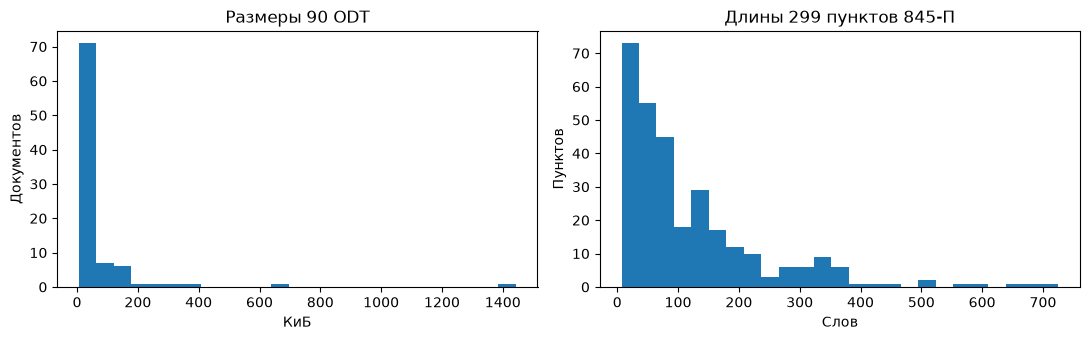

In [2]:
clauses = lengths[lengths.type == "clause"]
display(selected[["bytes", "chars", "words"]].describe(percentiles=[.5, .95]).round(1))
display(clauses[["chars", "words"]].describe(percentiles=[.5, .95]).round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
(selected.bytes / 1024).plot.hist(ax=axes[0], bins=25, title="Размеры 90 ODT")
axes[0].set(xlabel="КиБ", ylabel="Документов")
clauses.words.plot.hist(ax=axes[1], bins=25, title="Длины 299 пунктов 845-П")
axes[1].set(xlabel="Слов", ylabel="Пунктов")
plt.tight_layout()
plt.show()

Медиана длины пункта — **79 слов**, P95 — **357,3**, максимум — **725**. Размеры документов и пунктов неоднородны: одной средней недостаточно. Для объёмов стоит показывать также медиану, верхние перцентили и максимум.

## Частоты

Слова приведены к нижнему регистру; числа и маркеры изображений исключены. Лемматизация и удаление служебных слов не применяются. Поэтому предлоги и союзы закономерно занимают первые места. Частоты обозначений актов включают заголовки и повторные упоминания, а не только уникальные нормативные ссылки.

,term,count
0,в,84049
1,и,43820
2,по,35449
3,с,31837
4,на,24240
5,от,17390
6,россии,16704
7,о,15946
8,или,15190
9,банка,14551


,term,count
0,7047-У,585
1,590-П,516
2,199-И,441
3,6800-У,341
4,611-П,301
5,220-И,257
6,86-ФЗ,239
7,845-П,209
8,253-ФЗ,195
9,646-П,191


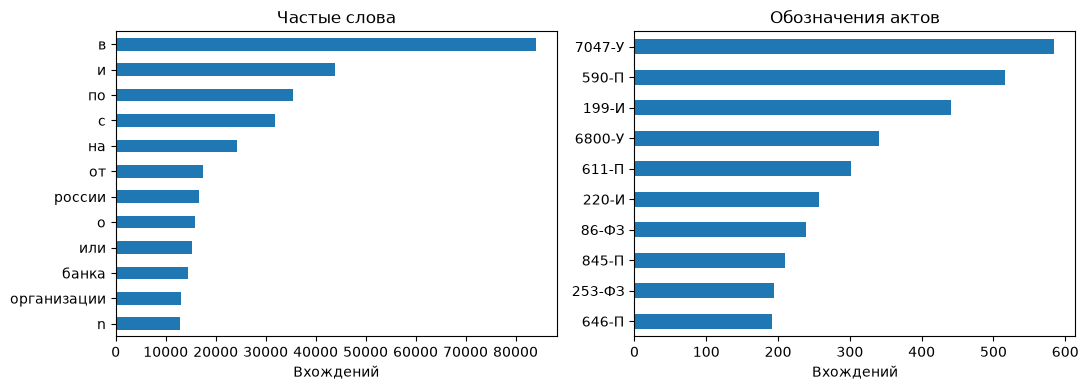

In [3]:
display(words.head(15))
display(acts.head(10))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
words.head(12).iloc[::-1].plot.barh(x="term", y="count", ax=axes[0], legend=False)
acts.head(10).iloc[::-1].plot.barh(x="term", y="count", ax=axes[1], legend=False)
axes[0].set(title="Частые слова", xlabel="Вхождений", ylabel="")
axes[1].set(title="Обозначения актов", xlabel="Вхождений", ylabel="")
plt.tight_layout()
plt.show()

В 90 выбранных источниках **1 889 816 вхождений слов**, **26 692 разных словоформы**. Среди обозначений актов чаще встречаются 7047-У, 590-П и 199-И. Частота не доказывает юридическую важность: длинные документы и повторяющиеся ссылки сильнее влияют на общий счётчик.

## Аномалии и дубли

В `anomalies.csv` одна строка означает выявленный случай: повторный текст, нетекстовое представление или пару «источник — URL отсутствующего файла». Отсутствие целевого файла в локальной выборке не означает, что URL не работает в интернете.

`845_p` и `411309161` — один нормализованный текст. `411309162` — карточка того же 845-П. Разные тексты одного акта не объединяются автоматически: при их обнаружении создаётся `edition_conflict`.

In [4]:
display(docs[~docs.selected][["file_id", "number", "role", "canonical_file_id"]])
display(anomalies.groupby("issue").size().rename("Случаев").to_frame())
display(selected.nlargest(5, "chars")[["file_id", "number", "chars", "words"]])

,file_id,number,role,canonical_file_id
3,107917,NaN,navigation,107917
46,411309161,845-П,act,845_p
47,411309162,845-П,registration_card,411309162


,Случаев
issue,
duplicate_text,1
non_text_source,2
target_missing,16144


,file_id,number,chars,words
26,406750235,6406-У,4139164,457750
10,185181,127-ФЗ,2523417,293876
23,406061235,809-П,1185268,128281
43,409466821,6800-У,801491,88530
82,73363119,199-И,708755,78775


## Статистика гиперссылок

Считаются вхождения ссылок, поэтому нужно суммировать `count`, а не количество строк CSV. `local_found` — найден локальный якорь; `target_present` — найден файл по ID в URL; `target_missing` — файла нет в выборке; `external_url` — другой внешний адрес, доступность которого не проверялась. Наличие файла не доказывает наличие нужного пункта или совпадение редакции.

,Вхождений во всём корпусе
status,
external_url,264
local_found,27863
target_missing,23258
target_present,15874


,Вхождений в 845-П
status,
local_found,636
target_present,209


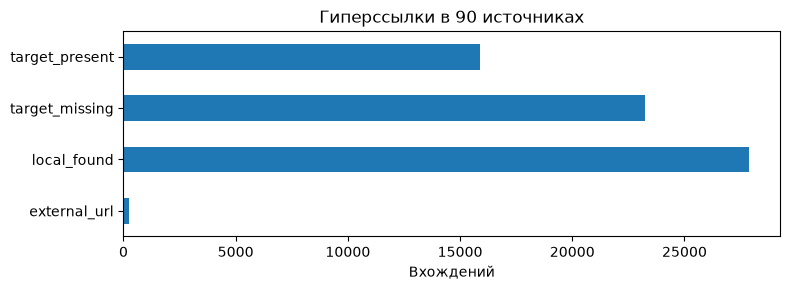

In [5]:
display(links.groupby("status")["count"].sum().rename("Вхождений во всём корпусе").to_frame())
display(links[links.file_id == "845_p"].groupby("status")["count"].sum().rename("Вхождений в 845-П").to_frame())
links.groupby("status")["count"].sum().plot.barh(figsize=(8, 3), title="Гиперссылки в 90 источниках")
plt.xlabel("Вхождений")
plt.ylabel("")
plt.tight_layout()
plt.show()

Во всём выбранном корпусе **67 259 гиперссылок**, из них **23 258 вхождений** ведут на отсутствующие в выборке файлы. Это ограничение охвата корпуса, а не 23 258 уникальных отсутствующих НПА.

В самом 845-П: **636 локальных ссылок** с найденными якорями и **209 ссылок на имеющиеся файлы**, включая ссылку на представление самого 845-П. Вложенные переходы за пределами 845-П покрыты неполно. Текстовые упоминания вида «пункт 10.19» этим небольшим скриптом не разрешаются.

## № 10. Полученный JSONL

368 структурных единиц: 299 нумерованных пунктов, 37 заголовков, 25 сносок и 7 прочих блоков. Сохранены 19 глав, 5 приложений, 12 таблиц и 57 вхождений изображений (44 разных файла). JSONL содержит очищенный текст и единые метаданные, а не retrieval-чанки.

Дата редакции неизвестна и остаётся `null`. Формулы сохранены исходными изображениями; их содержание не распознавалось.

In [6]:
corpus_path = ROOT / "data/processed/845_p/corpus.jsonl"
corpus = pd.read_json(corpus_path, lines=True)
display(corpus.groupby("type").size().rename("Записей").to_frame())
display(corpus[corpus.paragraph == "15.8.1"][["id", "number", "chapter", "paragraph", "text"]])

,Записей
type,
clause,299
context,5
footnote,25
heading,37
preamble,1
service,1


,id,number,chapter,paragraph,text
213,845p:main:15.8.1,845-П,15.0,15.8.1,15.8.1 Организационная независимость подраздел...
